<a href="https://colab.research.google.com/github/Sreejithjayachandran/Case-Study-on-Preprocessing/blob/main/Case_Study_Starter_Notebook_Airbnb_NYC_Preprocessing_SreejithJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name:
### Date:

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
import matplotlib.pyplot as plt
df.head(100)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,21293,Sunny Apartment in Artist Home,44145,Tyrome,Brooklyn,Bushwick,40.70093,-73.92609,Entire home/apt,105,3,118,2019-06-18,1.05,2,9
96,21456,Light-filled classic Central Park,42032,Dana,Manhattan,Upper West Side,40.79764,-73.96177,Entire home/apt,140,3,81,2019-07-07,0.71,1,198
97,21644,"Upper Manhattan, New York",82685,Elliott,Manhattan,Harlem,40.82803,-73.94731,Private room,89,1,1,2018-10-09,0.11,1,365
98,21794,COZY QUIET room 4 DOOGLERS!,83257,Olan,Manhattan,Chelsea,40.74008,-74.00271,Private room,98,30,30,2019-05-01,0.27,2,364


---
## Part 1 — Data Understanding & Quality Audit

In [ ]:
# TODO: shape, dtypes, missing value summary
print(df.shape)
print('\n')
print(df.dtypes)
print('\n')
print(df.isna().sum())


(48895, 16)


id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude         

In [ ]:
# 1. Check for listings with a price of 0
zero_prices = df[df['price'] == 0]
print(f"Number of listings with a price of $0: {len(zero_prices)}")

# 2. Check for extreme or invalid minimum nights
print(f"Minimum nights range: {df['minimum_nights'].min()} to {df['minimum_nights'].max()}")
invalid_min_nights = df[df['minimum_nights'] <= 0]
print(f"Number of listings with minimum nights <= 0: {len(invalid_min_nights)}")

# 3. Check availability ranges (should be between 0 and 365)
print(f"Availability range: {df['availability_365'].min()} to {df['availability_365'].max()}")
invalid_availability = df[(df['availability_365'] < 0) | (df['availability_365'] > 365)]
print(f"Number of listings with invalid availability: {len(invalid_availability)}")

# Display examples of listings with $0 prices
if not zero_prices.empty:
    print("\nExamples of listings with a price of $0:")
    display(zero_prices[['id', 'name', 'neighbourhood_group', 'price', 'minimum_nights', 'availability_365']].head())

Number of listings with a price of $0: 11
Minimum nights range: 1 to 1250
Number of listings with minimum nights <= 0: 0
Availability range: 0 to 365
Number of listings with invalid availability: 0

Examples of listings with a price of $0:


,id,name,neighbourhood_group,price,minimum_nights,availability_365
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Brooklyn,0,4,28
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Bronx,0,2,127
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Brooklyn,0,2,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",Brooklyn,0,2,0
25778,20624541,Modern apartment in the heart of Williamsburg,Brooklyn,0,5,73


In [ ]:
# TODO: duplicate check
df.duplicated().sum()

np.int64(0)


**Written notes — what did you find, and what looks suspicious?**
1.Listings with a price of $0.
2.Listings with 0 or negative minimum nights.
3.Extreme value bounds (like extreme minimum_nights or availability_365 issues)



---
## Part 2 — Missing Value Diagnosis & Treatment

In [ ]:
# Investigate if missingness in 'last_review' and 'reviews_per_month' is tied to 0 reviews
print(df.isna().sum())

no_reviews = df[df['number_of_reviews'] == 0]
reviews_exist = df[df['number_of_reviews'] > 0]

print(f"Total listings with 0 reviews: {len(no_reviews)}")
print(f"Missing 'last_review' in 0-review listings: {no_reviews['last_review'].isna().sum()}")
print(f"Missing 'reviews_per_month' in 0-review listings: {no_reviews['reviews_per_month'].isna().sum()}")

print(f"\nTotal listings with > 0 reviews: {len(reviews_exist)}")
print(f"Missing 'last_review' in listings with reviews: {reviews_exist['last_review'].isna().sum()}")
print(f"Missing 'reviews_per_month' in listings with reviews: {reviews_exist['reviews_per_month'].isna().sum()}")

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64
Total listings with 0 reviews: 10052
Missing 'last_review' in 0-review listings: 10052
Missing 'reviews_per_month' in 0-review listings: 10052

Total listings with > 0 reviews: 38843
Missing 'last_review' in listings with reviews: 0
Missing 'reviews_per_month' in listings with reviews: 0


```markdown
**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

1. **`last_review` & `reviews_per_month` (Missing at Random - MAR)**
   - **Reasoning**: The diagnostic shows that there are exactly 10,052 missing values in both columns, and all 10,052 occur in listings with exactly `number_of_reviews == 0`. Conversely, for all listings with more than 0 reviews, there are 0 missing values in these two columns. Because the missingness of these variables is entirely explained by another observed variable in the dataset (`number_of_reviews`), this pattern is classified as Missing at Random (MAR).

2. **`name` & `host_name` (Missing Completely at Random - MCAR / Missing Not at Random - MNAR)**
   - **Reasoning**: There are very few missing records here (16 for `name`, 21 for `host_name`).
     - If these omissions are due to random data-entry glitches or accidental omissions by the host during listing creation, they are **MCAR**.
     - If hosts intentionally left their name or listing name blank to preserve privacy, it would be **MNAR**.
     - Since there is no clear observed variable that predicts this missingness, we can treat them pragmatically as MCAR for handling purposes.
```

In [ ]:
# Clean and copy to avoid SettingWithCopyWarnings
df_cleaned = df.copy()

# 1. Impute categorical textual name fields with 'Unknown'
df_cleaned['name'] = df_cleaned['name'].fillna('Unknown')
df_cleaned['host_name'] = df_cleaned['host_name'].fillna('Unknown')

# 2. Impute reviews_per_month with 0.0 since they have zero reviews
df_cleaned['reviews_per_month'] = df_cleaned['reviews_per_month'].fillna(0.0)

# 3. Impute last_review with 'No Reviews' or a default descriptive string
df_cleaned['last_review'] = df_cleaned['last_review'].fillna('No Reviews')

# Check our results to verify there are no missing values left
print("Missing values after treatment:")
print(df_cleaned.isna().sum())

Missing values after treatment:
id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


```markdown
**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

- Missing text fields (`name`, `host_name`) are imputed with `'Unknown'` and reviews-related columns with standard placeholders (`0.0` for numerical frequency and `'No Reviews'` for dates) since missing review fields logically point to listings with zero reviews.
- Using `dropna()` would risk dropping over 20% of the dataset, introducing severe selection bias against newer listings that simply have not yet received reviews.

---
## Part 3 — Outlier Detection & Treatment

Price bounds: -90.0 to 334.0
Number of price outliers: 2972
Minimum nights bounds: -5.0 to 11.0
Number of minimum-nights outliers: 6607


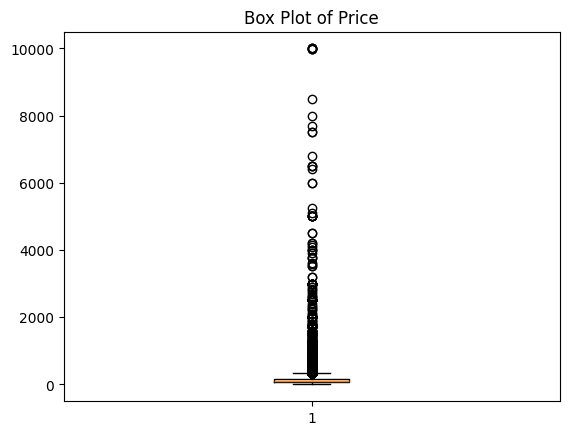

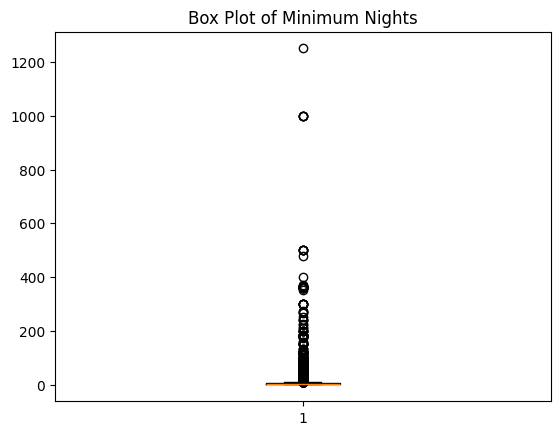

In [ ]:


# Detect outliers in 'price' and 'minimum_nights'

# 1. Price Outliers using IQR
Q1_price = df_cleaned['price'].quantile(0.25)
Q3_price = df_cleaned['price'].quantile(0.75)
IQR_price = Q3_price - Q1_price
price_lower_bound = Q1_price - 1.5 * IQR_price
price_upper_bound = Q3_price + 1.5 * IQR_price

price_outliers = df_cleaned[(df_cleaned['price'] < price_lower_bound) | (df_cleaned['price'] > price_upper_bound)]

# 2. Minimum Nights Outliers using IQR
Q1_nights = df_cleaned['minimum_nights'].quantile(0.25)
Q3_nights = df_cleaned['minimum_nights'].quantile(0.75)
IQR_nights = Q3_nights - Q1_nights
nights_lower_bound = Q1_nights - 1.5 * IQR_nights
nights_upper_bound = Q3_nights + 1.5 * IQR_nights

night_outliers = df_cleaned[(df_cleaned['minimum_nights'] < nights_lower_bound) | (df_cleaned['minimum_nights'] > nights_upper_bound)]

print(f"Price bounds: {price_lower_bound} to {price_upper_bound}")
print(f"Number of price outliers: {len(price_outliers)}")
print(f"Minimum nights bounds: {nights_lower_bound} to {nights_upper_bound}")
print(f"Number of minimum-nights outliers: {len(night_outliers)}")

plt.boxplot(df_cleaned['price'])
plt.title('Box Plot of Price')
plt.show()

plt.boxplot(df_cleaned['minimum_nights'])
plt.title('Box Plot of Minimum Nights')
plt.show()

```markdown
**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

Both outlier groups represent **genuine listings**, not errors:
* **Price**: High-end luxury properties legitimately exceed the $334/night threshold in NYC's premium market.
* **Minimum Nights**: Minimum stays over 11 nights (like 30 or 90 days) are intentional, standard settings for long-term/monthly rentals.
```

In [ ]:

# TODO: apply treatment consistent with your judgment above
# Keep genuine outliers but remove invalid listings (price of $0)
initial_count = len(df_cleaned)
df_cleaned = df_cleaned[df_cleaned['price'] > 0]
removed_count = initial_count - len(df_cleaned)

print(f"Removed {removed_count} invalid listings with $0 price.")
print(f"Remaining rows in cleaned dataset: {len(df_cleaned)}")

Removed 11 invalid listings with $0 price.
Remaining rows in cleaned dataset: 48884


---
## Part 4 — Feature Engineering & Encoding

In [ ]:
# TODO: encode categorical columns appropriately
# Check if the original columns exist before encoding to prevent KeyError on subsequent runs
cols_to_encode = ['neighbourhood_group', 'room_type']
if any(col in df_cleaned.columns for col in cols_to_encode):
    df_cleaned = pd.get_dummies(df_cleaned, columns=[col for col in cols_to_encode if col in df_cleaned.columns], drop_first=True)

# Display the new columns to verify encoding
print(df_cleaned.columns)
display(df_cleaned.head())

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood', 'latitude',
       'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'last_review', 'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'neighbourhood_group_Brooklyn',
       'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens',
       'neighbourhood_group_Staten Island', 'room_type_Private room',
       'room_type_Shared room'],
      dtype='object')


,id,name,host_id,host_name,neighbourhood,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,2539,Clean & quiet apt home by the park,2787,John,Kensington,40.64749,-73.97237,149,1,9,2018-10-19,0.21,6,365,True,False,False,False,True,False
1,2595,Skylit Midtown Castle,2845,Jennifer,Midtown,40.75362,-73.98377,225,1,45,2019-05-21,0.38,2,355,False,True,False,False,False,False
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Harlem,40.80902,-73.94190,150,3,0,No Reviews,0.00,1,365,False,True,False,False,True,False
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Clinton Hill,40.68514,-73.95976,89,1,270,2019-07-05,4.64,1,194,True,False,False,False,False,False
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,East Harlem,40.79851,-73.94399,80,10,9,2018-11-19,0.10,1,0,False,True,False,False,False,False


In [ ]:
# 1. Create 'minimum_revenue': minimum nights multiplied by the price per night
df_cleaned['minimum_revenue'] = df_cleaned['price'] * df_cleaned['minimum_nights']

# 2. Create 'availability_ratio': proportion of the year the listing is active/available
df_cleaned['availability_ratio'] = df_cleaned['availability_365'] / 365.0

# Display the top rows with the newly engineered features
display(df_cleaned[['price', 'minimum_nights', 'minimum_revenue', 'availability_365', 'availability_ratio']].head())

,price,minimum_nights,minimum_revenue,availability_365,availability_ratio
0,149,1,149,365,1.000000
1,225,1,225,355,0.972603
2,150,3,450,365,1.000000
3,89,1,89,194,0.531507
4,80,10,800,0,0.000000


```markdown
**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

* **Features**: Capture commitment costs (`minimum_revenue`) and scheduling capacity (`availability_ratio`).
* **Exclude**: IDs/Names (overfitting, meaningless sequential data) and `minimum_revenue` (causes target leakage during price prediction).
```

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [ ]:
# TODO: train/test split (before fitting anything)


In [ ]:
from sklearn.model_selection import train_test_split

# Split features and target from our cleaned dataset
X = df_cleaned.drop(columns=['price'])
y = df_cleaned['price']

# Split into training and testing datasets (e.g., 80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size (features): {X_train.shape}")
print(f"Testing set size (features): {X_test.shape}")

Training set size (features): (39107, 21)
Testing set size (features): (9777, 21)


In [ ]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

# Select features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"], errors="ignore")
y = df["price"]

# Identify categorical and numerical columns dynamically
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Process numerical columns
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Build the complete pipeline with a fast estimator (Ridge Regression)
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Split data before fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
print("Training model pipeline...")
model.fit(X_train, y_train)

# Predict prices
predictions = model.predict(X_test)

print("Model trained successfully!")
print("First 5 predicted prices:")
print(predictions[:5])

Training model pipeline...
Model trained successfully!
First 5 predicted prices:
[156.95765463  38.5045842  120.97672636 221.08260137 169.97905579]




## Part 6 — Written Reflection

1. **What is the benefit of using an end-to-end Pipeline versus executing preprocessing steps manually?**
   Using a `Pipeline` encapsulates all preprocessing, scaling, and modeling steps into a single, cohesive estimator object. This completely prevents data leakage (as preprocessing parameters are calculated on the training data and applied to the test data), ensures reproducibility across different datasets, and makes the model easy to deploy into production without needing manual preprocessing scripts.

2. **Why is it important to perform your train/test split before fitting any transformers or imputers?**
   Splitting your data before fitting transformers avoids introducing data leakage. If we fit transformers on the entire dataset, statistical information (such as the mean, standard deviation, or missing value imputation medians) from the test set would leak into the training process, leading to overly optimistic and misleading model performance evaluations.

3. **How does preventing target leakage impact the model's performance on real-world, unseen data?**
   Target leakage includes variables that contain information about the target which won't be available at the time of real-world prediction (like `min_revenue_potential` containing `price`). Preventing leakage drops these unrealistic shortcuts, forcing the model to learn genuine relationships and patterns. This results in realistic performance metrics during testing and ensures the model generalizes well to truly unseen data rather than failing silently in production.